# Support Vector Machines and Kernels


## Înainte de rulare
Am folosit fișierul `Wine_Quality_Data.csv` din folderul `data`. Celulele se rulează în ordine, de sus în jos. Sunt necesare numpy, pandas, matplotlib, seaborn, scikit-learn și IPython. Am păstrat `random_state=42` pentru a putea repeta experimentul cu aceeași împărțire a datelor. Pentru aceste exerciții nu este nevoie de sklearnex.

# Obiectivele cursului
- Aplicarea metodei vectorilor de suport (SVM) — un algoritm popular utilizat pentru sarcini de clasificare
- Recunoașterea similitudinii dintre SVM și regresia logistică
- Calcularea funcției de pierdere pentru SVM
- Aplicarea regularizării în SVM și studierea recomandărilor privind obținerea unei clasificări neliniare cu ajutorul SVM

## Introducere
În aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține o măsură a calității (de la 3 la 9, unde scorul cel mai mare indică cea mai bună calitate) și culoarea (roșu sau alb). Numele fișierului: `Wine_Quality_Data.csv`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import make_pipeline
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 20)
data = pd.read_csv(Path('data') / 'Wine_Quality_Data.csv')
assert data.isna().sum().sum() == 0, 'Verificați valorile lipsă.'
assert set(data.color.unique()) == {'red', 'white'}
print('Dimensiune:', data.shape)
print('Valori lipsă:', data.isna().sum().sum())
print('Rânduri duplicate:', data.duplicated().sum())
display(data.head())
display(data.describe())


Dimensiune: (6497, 13)
Valori lipsă: 0
Rânduri duplicate: 1177


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


## Întrebarea 1
* Importul datelor.
* Creați variabila țintă `y` sub forma unei coloane cu valori 1/0, unde 1 înseamnă vin roșu.
* Creați un grafic pereche pentru setul de date.
* Creați un grafic cu bare care să ilustreze corelația dintre fiecare coloană și `y`.
* Selectați cele două câmpuri cu cea mai mare corelație (folosind valorile corelației absolute) și creați `X`.
* Folosiți MinMaxScaler pentru a scala `X`. Rețineți că rezultatul va fi un np.array. Transformați-l din nou într-un DataFrame și redenumiți coloanele în consecință.

Caracteristici selectate: ['total_sulfur_dioxide', 'volatile_acidity']


,corelație cu y
total_sulfur_dioxide,-0.700357
volatile_acidity,0.653036
chlorides,0.512678
sulphates,0.487218
fixed_acidity,0.486740
free_sulfur_dioxide,-0.471644
density,0.390645
residual_sugar,-0.348821
pH,0.329129
citric_acid,-0.187397


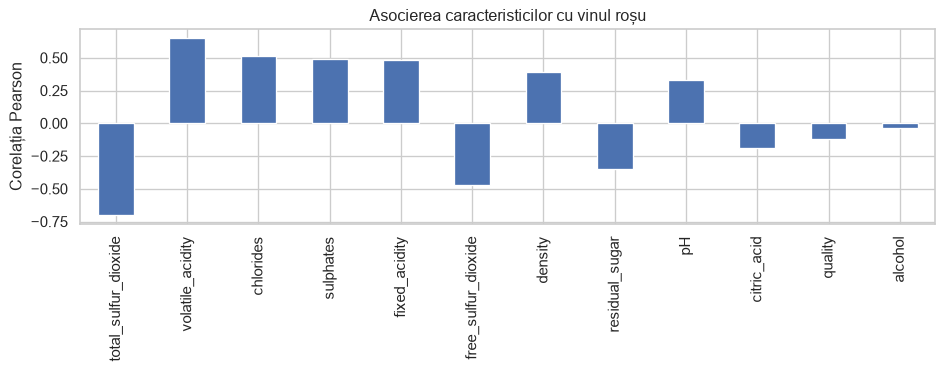

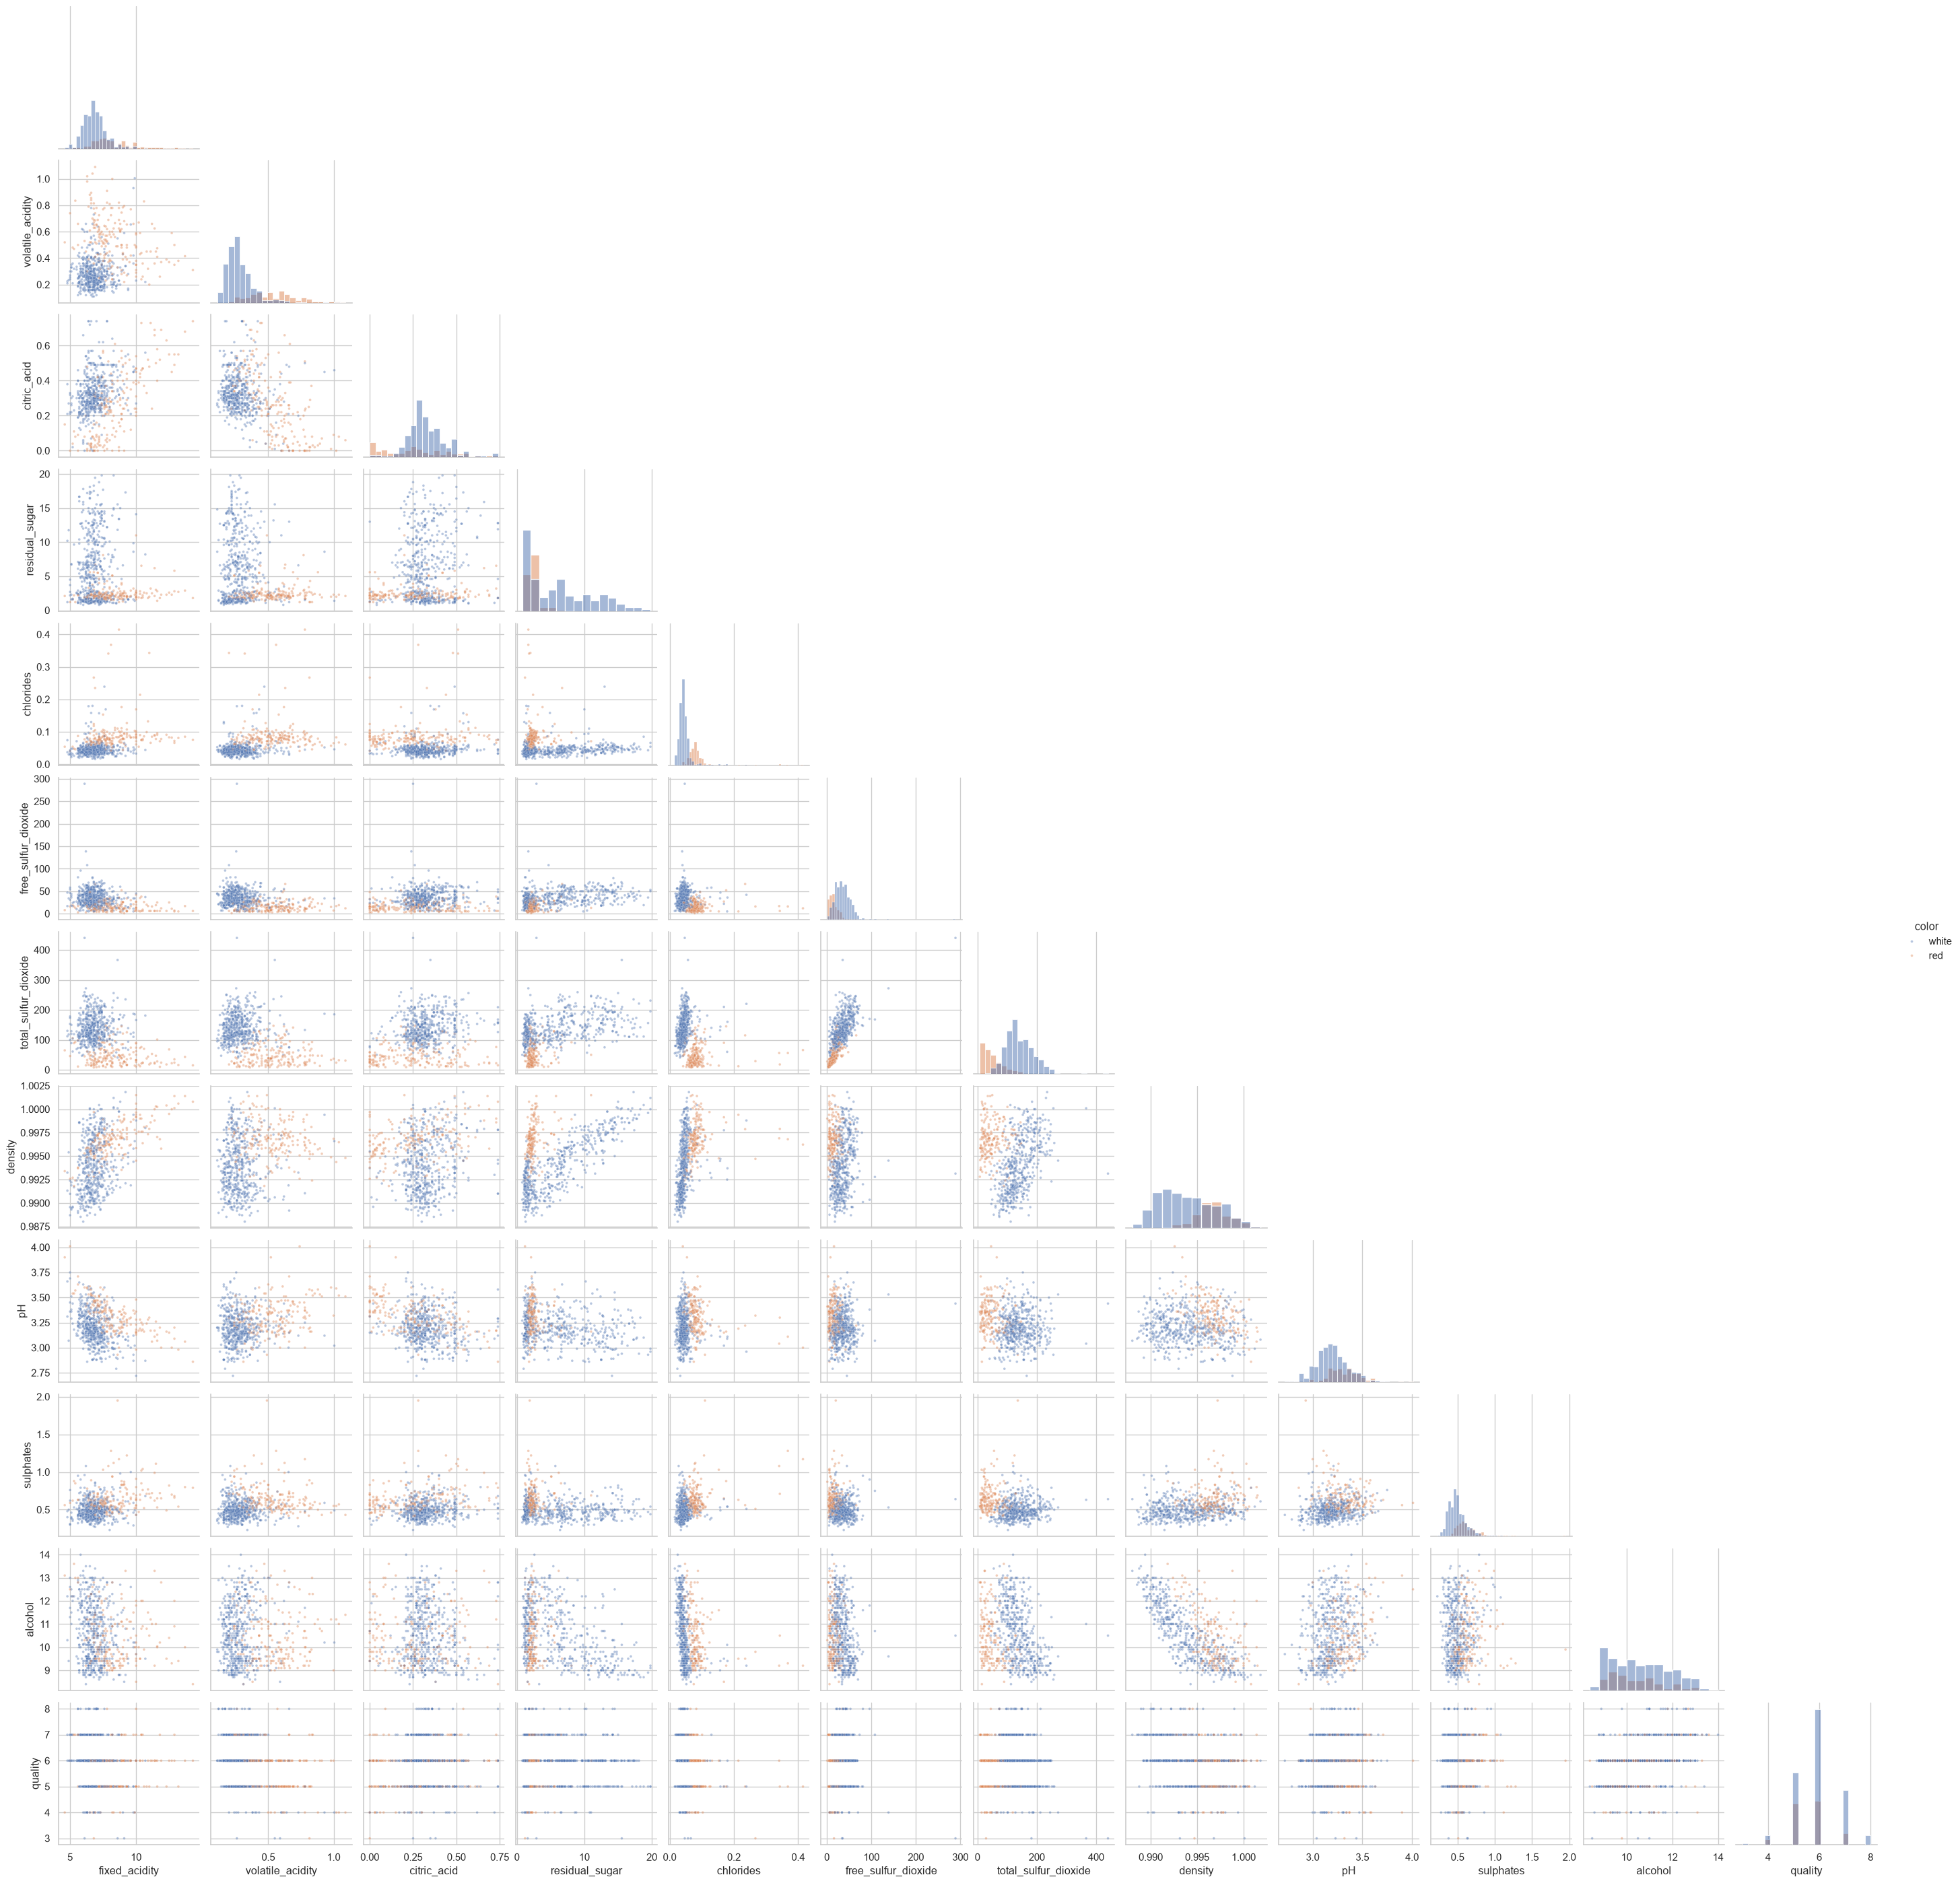

,total_sulfur_dioxide,volatile_acidity
0,0.064516,0.413333
1,0.140553,0.533333
2,0.110599,0.453333
3,0.124424,0.133333
4,0.064516,0.413333


In [2]:
from sklearn.svm import LinearSVC, SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
y = data.color.map({'white': 0, 'red': 1}).rename('red')
features = data.drop(columns='color')
correlations = features.corrwith(y).sort_values(key=abs, ascending=False)
display(correlations.to_frame('corelație cu y'))
correlations.plot.bar(figsize=(10,4), ylabel='Corelația Pearson', title='Asocierea caracteristicilor cu vinul roșu')
plt.tight_layout(); plt.show()
# Folosesc 700 de rânduri, ca să nu se suprapună prea multe puncte în grafic.
pair_data = data.sample(n=min(700,len(data)), random_state=RANDOM_STATE)
sns.pairplot(pair_data, hue='color', corner=True, diag_kind='hist', plot_kws={'s':8,'alpha':0.4})
plt.show()
selected = correlations.index[:2].tolist()
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(features[selected]), columns=selected, index=data.index)
print('Caracteristici selectate:', selected)
display(X.head())

Am ales `total_sulfur_dioxide` și `volatile_acidity`, deoarece au cele mai mari corelații în valoare absolută cu ținta. Contează cât de puternică este legătura, indiferent de semnul ei. Am notat vinul roșu cu 1 și vinul alb cu 0, apoi am adus cele două caracteristici în intervalul [0, 1].

Pentru pairplot am folosit 700 de observații, ca să se distingă mai ușor punctele. În această etapă explorez datele, așa că am făcut selecția și scalarea pe tot setul. Pentru o evaluare pe date noi, acești pași ar trebui făcuți doar pe datele de antrenare.

## Întrebarea 2

Scopul acestei întrebări este de a analiza pragul de decizie al clasificatorului LinearSVC pentru setul de date dat. Consultați [acest exemplu](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) din documentația sklearn.

* Configurați clasificatorul LinearSVC pe `X` și `y`.
* Selectați 300 de eșantioane din `X`. Obțineți valorile corespunzătoare ale `y`. Salvați-le în variabilele `X_color` și `y_color`. Acest lucru se datorează faptului că setul de date original este prea mare și generează un grafic supraîncărcat.
* Modificați `y_color` astfel încât valoarea „roșu” să înlocuiască 1, iar „galben” să înlocuiască 0.
* Graficul de dispersie pentru coloanele X_color. Utilizați argumentul cu cuvântul-cheie „color=y_color” pentru a afișa codul culorii.
* Utilizați fragmentul de cod de mai jos pentru a desena suprafața soluției în culori.


python

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)

xx, yy = np.meshgrid(x_axis, y_axis)

xx_ravel = xx.ravel()

yy_ravel = yy.ravel()

X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T

y_grid_predictions = *[MODELUL DVS.]*. predict(X_grid)

y_grid_predictions = y_grid_predictions.reshape(xx.shape)

ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)


Nu ezitați să experimentați cu diferite variante de parametri pentru LinearSVC și să examinați marginile de decizie.

Acuratețe descriptivă pe antrenare: 0.9546


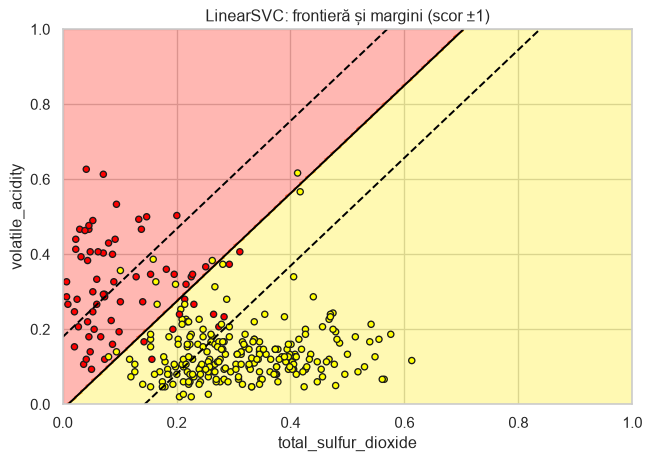

In [3]:
linear_model = LinearSVC(C=1, max_iter=20000, random_state=RANDOM_STATE)
linear_model.fit(X, y)
X_color = X.sample(n=300, random_state=RANDOM_STATE)
y_color = y.loc[X_color.index].map({1:'red',0:'yellow'})
x_axis = np.arange(0,1.005,.005)
xx, yy = np.meshgrid(x_axis,x_axis)
X_grid = pd.DataFrame(np.c_[xx.ravel(),yy.ravel()], columns=X.columns)
pred = linear_model.predict(X_grid).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7,5))
ax.contourf(xx,yy,pred,cmap=plt.cm.autumn_r,alpha=.3)
ax.scatter(X_color.iloc[:,0],X_color.iloc[:,1],color=y_color,edgecolors='k',s=22)
scores = linear_model.decision_function(X_grid).reshape(xx.shape)
ax.contour(xx,yy,scores,levels=[-1,0,1],colors='black',linestyles=['--','-','--'])
ax.set(xlabel=X.columns[0],ylabel=X.columns[1],title='LinearSVC: frontieră și margini (scor ±1)')
plt.tight_layout(); plt.show()
print('Acuratețe descriptivă pe antrenare:', round(linear_model.score(X,y),4))

Dreapta continuă separă cele două clase, iar liniile întrerupte arată marginile, unde scorul modelului este −1 sau 1. Punctele aflate în zona celeilalte clase sunt clasificate greșit.

Modelul a obținut o acuratețe de aproximativ 95,46% pe datele de antrenare. Rezultatul arată că cele două caracteristici ajută la separarea vinurilor, dar încă nu spune cât de bine se va descurca modelul pe date noi.

## Întrebarea 3

Să extindem acum nucleul Gauss al SVC și să vedem cum se modifică limita de decizie.

* Combinați fragmentele de cod din întrebarea 2 într-o singură funcție, care utilizează estimatorul `X` și `y` și va genera graficul final cu limita de decizie. Pași:
    <ol>
     <li> modelul potrivit
     <li> obțineți un eșantion de 300 de înregistrări din X și valorile corespunzătoare ale lui y
     <li> creați o rețea, faceți predicții, generați un grafic folosind ax.contourf
     <li> adăugați-l la graficul dispersat
    </ol>
* După copierea și inserarea codului, asigurați-vă că funcția finală utilizează `estimatorul` dvs. de intrare, nu modelul LinearSVC creat de dvs.
* Pentru următoarele valori ale lui `gamma`, creați un SVC cu kernel gaussian și desenați curba de decizie.
`gammas = [.5, 1, 2, 10]`
* Menținând `gamma` constantă, pentru diferite valori ale lui `C`, desenați curba de decizie. Puteți încerca
`Cs = [.1, 1, 10]>

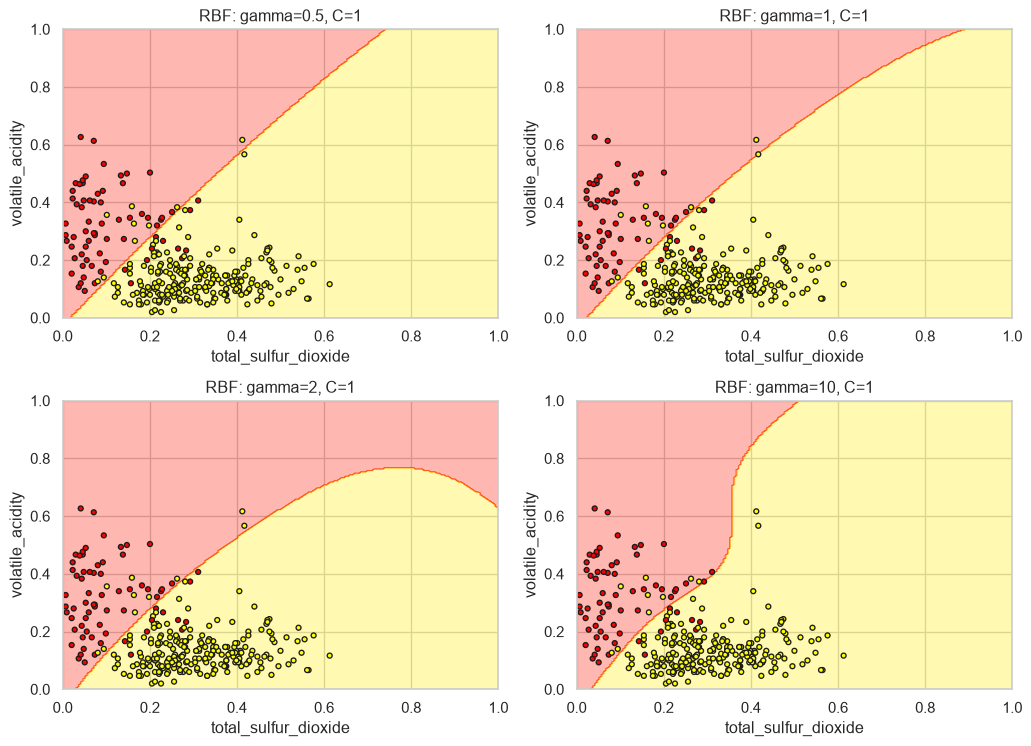

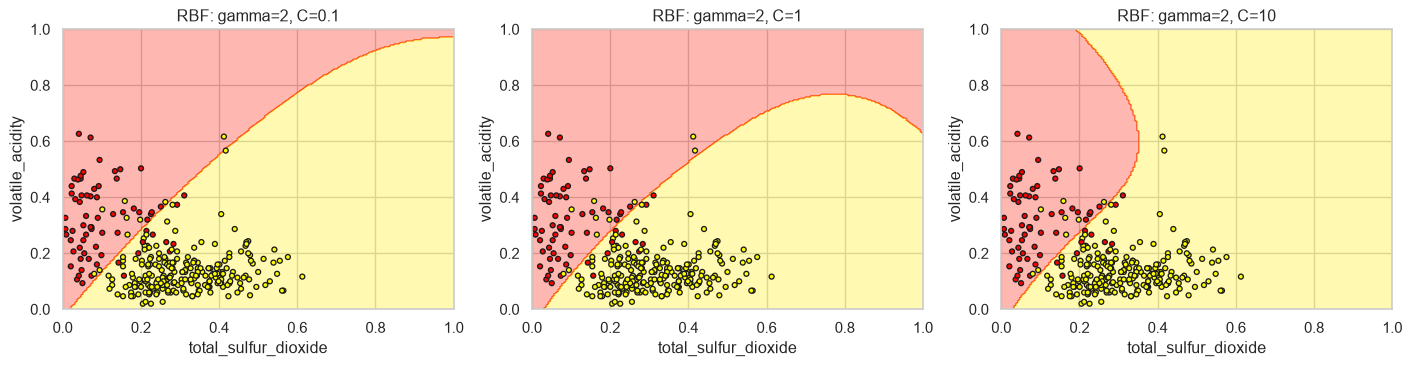

In [4]:
def plot_boundary(estimator, X, y, ax=None, title=None):
    estimator.fit(X,y)
    sample = X.sample(n=min(300,len(X)),random_state=RANDOM_STATE)
    colors = y.loc[sample.index].map({1:'red',0:'yellow'})
    axis = np.arange(0,1.005,.005)
    gx,gy = np.meshgrid(axis,axis)
    grid = pd.DataFrame(np.c_[gx.ravel(),gy.ravel()],columns=X.columns)
    prediction = estimator.predict(grid).reshape(gx.shape)
    if ax is None: _,ax=plt.subplots(figsize=(6,4))
    ax.contourf(gx,gy,prediction,cmap=plt.cm.autumn_r,alpha=.3)
    ax.scatter(sample.iloc[:,0],sample.iloc[:,1],color=colors,edgecolors='k',s=14)
    ax.set(xlabel=X.columns[0],ylabel=X.columns[1],title=title)
    return estimator
fig, axes = plt.subplots(2,2,figsize=(11,8))
for gamma,ax in zip([.5,1,2,10],axes.flat):
    plot_boundary(SVC(kernel='rbf',gamma=gamma,C=1),X,y,ax,f'RBF: gamma={gamma}, C=1')
plt.tight_layout(); plt.show()
fig,axes = plt.subplots(1,3,figsize=(15,4))
for c,ax in zip([.1,1,10],axes):
    plot_boundary(SVC(kernel='rbf',gamma=2,C=c),X,y,ax,f'RBF: gamma=2, C={c}')
plt.tight_layout(); plt.show()

Cu kernelul RBF, separarea claselor nu mai este limitată la o dreaptă. Am variat mai întâi `gamma`, păstrând `C=1`. La valori mici ale lui `gamma`, fiecare punct influențează o zonă mai largă, iar frontiera tinde să fie mai netedă. La valori mai mari, modelul poate urmări mai atent particularitățile locale.

În al doilea experiment am păstrat `gamma=2` și am schimbat `C`. Un `C` mic permite mai multe încălcări ale marginii, iar un `C` mare le penalizează mai mult. O frontieră mai complicată nu înseamnă automat un model mai bun; pentru alegerea parametrilor ar trebui comparate și rezultatele pe validare.

## Întrebarea 4

În această întrebare vom compara timpul de execuție între SVC și Nystroem cu nucleul rbf.
<br><br>
Jupyter Notebooks oferă o funcție magică utilă, **`%timeit`**, care execută un șir de comandă și afișează timpul necesar pentru execuție. Dacă introduceți **`%timeit`** la începutul unei celule, aceasta va rula întreaga celulă și va afișa timpul de execuție.

* Reîncărcați datele privind calitatea vinului dacă ați adus modificări la original.
* Creați variabila `y` din coloana `data.color` și `X` din celelalte coloane.
* Folosiți `%%timeit` pentru a măsura timpul necesar configurării SVC cu nucleul RBF.
* Folosiți `%%timeit` pentru a măsura timpul necesar următoarei operațiuni: ordonați datele folosind Nystroem, apoi integrați clasificatorul SGD.

Nystroem+SGD va necesita mult mai puțin timp pentru antrenare. Această diferență va fi mai pronunțată dacă setul de date ar fi mai mare.

* Faceți 5 copii ale lui X și corelați-le
* Faceți 5 copii ale lui y și corelați-le
* Comparați timpul necesar pentru antrenarea ambelor metode de mai sus.

In [5]:
from time import perf_counter
from IPython import get_ipython
X_all = data.drop(columns='color')
y_all = data.color.map({'white':0,'red':1})
# Măsor și timpul de scalare, pentru ambele metode.
def exact_svm():
    return make_pipeline(StandardScaler(),SVC(kernel='rbf',gamma=.1,C=1,cache_size=500))
def approx_svm():
    return make_pipeline(StandardScaler(),Nystroem(kernel='rbf',gamma=.1,n_components=100,random_state=42),
                         SGDClassifier(loss='hinge',alpha=.0001,max_iter=3000,tol=.001,random_state=42))
X_five = pd.concat([X_all]*5,ignore_index=True)
y_five = pd.concat([y_all]*5,ignore_index=True)
# Repet fiecare antrenare de 3 ori, cu timeit în Jupyter.
# Salvez timpii ca să îi pot compara în tabel.
ip = get_ipython()
benchmarks=[]
for label, xb, yb in [('original',X_all,y_all),('5 copii',X_five,y_five)]:
    for name,factory in [('SVC RBF',exact_svm),('Nystroem + SGD',approx_svm)]:
        if ip is not None:
            timer = ip.run_cell_magic('timeit','-n 1 -r 3 -o','factory().fit(xb,yb)')
            times = timer.all_runs
        else:
            times=[]
            for _ in range(3):
                start=perf_counter(); factory().fit(xb,yb); times.append(perf_counter()-start)
        benchmarks.append({'date':label,'metoda':name,'n':len(xb),'timp_mediu_s':np.mean(times),'std_s':np.std(times)})
timings=pd.DataFrame(benchmarks)
display(timings)
for label in timings.date.unique():
    t=timings[timings.date==label].set_index('metoda').timp_mediu_s
    print(f'{label}: raport timp SVC / aproximare = {t["SVC RBF"]/t["Nystroem + SGD"]:.2f}')
# Verific separat și acuratețea, pe o împărțire train/test.
xa,xt,ya,yt=train_test_split(X_all,y_all,test_size=.2,stratify=y_all,random_state=42)
for name,factory in [('SVC RBF',exact_svm),('Nystroem + SGD',approx_svm)]:
    model=factory().fit(xa,ya)
    print(name, 'acuratețe test:', round(model.score(xt,yt),4))

original: raport timp SVC / aproximare = 1.97
5 copii: raport timp SVC / aproximare = 4.96
SVC RBF acuratețe test: 0.9969
Nystroem + SGD acuratețe test: 0.9938


,date,metoda,n,timp_mediu_s,std_s
0,original,SVC RBF,6497,0.151997,0.005611
1,original,Nystroem + SGD,6497,0.077173,0.014701
2,5 copii,SVC RBF,32485,1.657768,0.159365
3,5 copii,Nystroem + SGD,32485,0.333985,0.021477


Pe setul inițial, Nystroem + SGD s-a antrenat de aproximativ 1,97 ori mai repede decât SVC. După repetarea datelor de cinci ori, diferența a crescut la aproximativ 4,96 ori. În acest experiment, aproximarea a redus timpul de antrenare, mai ales pentru volumul mai mare de date.

Nystroem transformă datele în 100 de caracteristici care aproximează kernelul RBF, apoi SGD antrenează un clasificator liniar. Pe test, SVC a obținut aproximativ 99,69%, iar Nystroem + SGD aproximativ 99,38%. Am obținut astfel un timp mai mic, cu o ușoară scădere a acurateții.

Cele cinci copii conțin aceleași observații, deci măresc doar volumul de calcul. Am verificat acuratețea separat, pe datele originale. Timpii pot fi diferiți pe alt calculator sau la o altă rulare.

## Rezultatele obținute

Am păstrat mai jos valorile obținute la rulare. Timpii de antrenare pot varia dacă repet experimentul.

```text
Caracteristici selectate: ['total_sulfur_dioxide', 'volatile_acidity']

Acuratețe descriptivă pe antrenare: 0.9546

original: raport timp SVC / aproximare = 1.97
5 copii: raport timp SVC / aproximare = 4.96
SVC RBF acuratețe test: 0.9969
Nystroem + SGD acuratețe test: 0.9938
```